# Building an engineering agent for PLE: lab journal

A living record of how our entry to the *Physical-Engineering's Last Exam* competition is built:
what we measured, what we observed, and why each part of the harness exists. It is the source for
the competition write-up.

Every number below is read from the run tracker (`research/runs.jsonl`) when the notebook runs.
The story so far, in order: **(1)** a cloud VM so we can judge exactly, **(2)** a split of the
dev set in two, **(3)** a very simple naive test with just a model.

## Write-up tracker

The final upload is written from this notebook, against the competition's judging criteria
(from the Kaggle page; 100 points in all).
Status: `todo` / `draft` / `done`. Update the table in `research/build_journal.py`, then rebuild.

| # | Criterion (points) | What judges look for | What we have / still need | Status |
|---|---|---|---|---|
| 1 | **Insight & failure analysis** (25) | Something non-obvious; real dev-set failures; controlled ablations ("we added X, score went A to B"); ideas that failed | Section 6: the agent writes its own checks and gets the scope wrong (6a); failure analysis of 18 runs against four hypotheses (6b); the engine and what it provides (6c); rung 3 version by version with five findings: the biggest lever was enabling ifcopenshell, not the engine; a tool failing silently in the evaluator environment; the score plateau at the checks' scope; the optimizer amplifying check error (two of three runs fell to 0.000); rewriting the checker did not loosen checks (6d). Need: the engine-off ablation, more repeats, a second task | draft |
| 2 | **Engineering reasoning** (25) | One concrete dev task walked through, our agent's trajectory against a licensed engineer's workflow: where it held up, where it took shortcuts, which domain skills separated pass from fail | Section 6d has the sprinkler-head case: drawing says 1,890 mm, code says 2,600 mm, every agent built the drawing and scoped the headroom check to routes. Need: the full trajectory of one run laid against an engineer's workflow, step by step | draft |
| 3 | **Cross-model generalizability** (15) | All 29 dev tasks with at least two models, ideally across families; which changes help every model, which only one; how model choice shifts accuracy and token cost; comparison table in the write-up; one target `google-cloud/<id>` committed in `submission.yaml` for Stage 2 | Rung 0 runs two models on half A only. Need: every rung on 2+ models, a final pass over all 29 (half B needs a stated reason), and the single target model chosen | todo |
| 4 | **Efficiency & scaling** (20) | Dev score against compute budget (calls, tokens, runtime or parallel verification attempts); where accuracy plateaus; remaining headroom | Calls, tokens and minutes per rung version are generated into the table in 6b (rung 3 uses 9 to 12 designer calls of 40, plus the second reader's own budget). The optimizer spends dozens of designs inside one tool call with no model calls. The plateau at 0.92 is explained (6d). Need: a score-vs-calls chart per rung and one budget knob varied | draft |
| 5 | **Clarity & visuals** (15) | Written for an ML researcher with no civil, mechanical or electrical background; headline finding near the top; the 3 required figures; under 2,000 words | Five schematics are drawn (`docs/figures.md`: how a run works, the ladder, the agent loop, the rung 3 workflow, what we provide); the three to use are still to be chosen. Need: a plain-language glossary, the headline finding at the top, and the word count checked at the end | draft |

Gate: the top 100 submissions from Stage 1 advance to Stage 2, and an entry must first pass the
automated `kit check` and artifacts verification before its write-up is scored.

Also needed, from our own plan: the evaluation setup (section 2), the split and hold-out
discipline (section 3), the final architecture (`docs/architecture.md`,
`docs/design-decisions.md`) and how to reproduce (`infra/`).

## 1. The problem

PLE has 85 real engineering tasks: structural, civil, electrical and mechanical. Each runs in an
isolated container with the project's files and up to 6 hours, and asks for a real deliverable: a
calculation package, a coordinated IFC model, a review memo. Tasks are graded `0`-`1` by
programmatic checks, by an LLM judge against an expert rubric, or both.

An entry is a **harness**, the code that drives a model through each task, paired with one of the
Google-sponsored models. The best stock setup on the public leaderboard (Gemini 4 Neon with
Google's own agent) scores **0.507** on the 56 hidden tasks: about half the available points.

## 2. An evaluation environment in a cloud VM

**Why.** We want to judge our harness *exactly* as the competition does: its own task images,
its own graders, the same protocol. That needs Docker with real memory (some tasks run app
servers and need up to 16 GB), and a model endpoint for both the harness and the judge.

**The idea in one sentence.** Every run happens in a cloud environment we built to look like the evaluation
environment as closely as we could, so that what we measure on the development tasks is what the evaluation would
measure.

**Where it matches** (checked against the organizers' own files and our run records):

* The runner, graders and task images are the organizers' own, from their repository at one recorded commit with no
  local changes. Each run record stores that commit.
* Each task runs in its own container with the CPUs and memory the task declares, no network, and our harness in a
  separate container, talking to it over the competition's protocol.
* The models are reached through the organizers' own proxy configuration, with the same model names, backed by
  Vertex AI, and the default reasoning level is the models' highest, as in the evaluation.

**Where it does not match** (stated so the numbers are read correctly):

* Judged tasks use Gemini 4 Neon as judge, the leaderboard uses Claude Opus 5.5 (below). The task this write-up
  studies is graded by plain code, so its scores are not affected.
* Our machine is far larger (32 CPUs); it only decides how many trials run side by side.
* The backend behind the real sponsored model endpoint is not documented; ours is Vertex AI in our own project.
* We have only the 29 development tasks, not the hidden test set.

**What we set up**

* One VM (`ple-runner`, spot `n2-standard-32`, 250 GB, Docker + Harbor) in our own Google Cloud
  project, running the competition's `eval/run.py` unchanged. It powers itself off after 30 idle
  minutes and after 24 h, so a forgotten VM cannot run up a bill.
* The competition's model proxy on the VM, calling Vertex AI as the VM's own service account (no
  keys stored).
* A budget of 600 DKK a month with alerts, and a **hard cap** that switches billing off at 100 %.
* Control from a cloud session, with no laptop: a GitHub Actions workflow starts the VM, runs a
  job script on it and reads the log back. Google trusts GitHub's identity for this one
  repository (workload identity federation), so no keys are stored.

**Why not the laptop.** Docker Desktop on the 8 GB Mac had 3.8 GB, too little for the larger
tasks, and the laptop later broke.

**Caveat on the judge.** The leaderboard judges rubric tasks with Claude Opus 5.5. Our project
has no Vertex quota for it (three increase requests were auto-denied), so development runs use
Gemini 4 Neon as judge. Judged scores are therefore *approximate*; we only compare runs that
share a judge, and the tracker refuses to merge runs with different judges.

## 3. Splitting the dev set in two

**A split we don't cheat on.** The 29 public dev tasks are split in two. We develop only on
**half A** (15 tasks). **Half B** (14 tasks) is held out and run rarely, to check that what helps
on A carries over to tasks we have never looked at; the tracker refuses to record a half-B run
without a stated reason. Five tasks we had studied in detail before splitting were placed in A by
construction; the rest were assigned at random (fixed seed), balanced by grading type.

In [1]:
import json, pathlib, sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = pathlib.Path.cwd()
sys.path.insert(0, str(HERE))
import tracker

split = tracker.load_split()
rows = [{"half": h, "task": t, **{k: split["tasks"][t][k] for k in ("grading", "domain")}}
        for h in ("A", "B") for t in split[h]]
tasks = pd.DataFrame(rows)
print(f"seed {split['seed']} · {split['method']}")
pd.crosstab(tasks["grading"], tasks["half"], margins=True, margins_name="total")

seed 20261124 · already-studied tasks fixed in A; the rest assigned at random per grading type


half,A,B,total
grading,,,
checks,6,6,12
checks-judge,2,1,3
rubric,7,7,14
total,15,14,29


In [2]:
tasks[tasks.half == "A"][["task", "grading", "domain"]].reset_index(drop=True)

,task,grading,domain
0,data-hall-mep-routing,checks,Mechanical engineering
1,fire-test-validation-memo,rubric,Mechanical engineering
2,eor-review-corrections,checks-judge,Structural engineering
3,data-center-site-model,checks,Civil engineering
4,solar-witness-test-package,rubric,Electrical engineering
5,frame-extension-method,checks,Civil engineering
6,fire-solve-convergence,rubric,Mechanical engineering
7,les-mesh-resolution,rubric,Mechanical engineering
8,division-26-specifications,checks,Electrical engineering
9,wind-diaphragm-shear,checks,Structural engineering


> **Status (2026-11-26): rung 0 has its first valid result: v5 (single call, images attached, low
> reasoning effort).** Runs run-001 to run-008 stay in the tracker flagged `INVALID` with their reasons
> (blind to images, then a thinking budget that left no room to answer). See the lab log.

## 4. Rung 0: a naive test with just a model

**Design.** One model call, no tools, no agent loop. Before the call the harness (not the model)
turns the task's files into plain text and pastes them after the task text; images are listed by
name only. The model answers once; files it writes as marked blocks in its answer are saved in
the task container, and the rest of the answer is the final message. It cannot open files or run
anything. It lives in `harnesses/naive/`.

**Why start here.** It is the floor every later rung is measured against. If a tool loop does not
beat it, the loop is not earning its cost.

**Known limits, by design.** It can only write text files (no xlsx, docx or images), and it never
checks its own work. We expect it to fail on those tasks, and *which* tasks it fails is the point.

**The comparison.** The same harness with two models: Gemini 3.8 Flash (the "bad" model) and
Gemini 4 Neon (the "better" one), over all of half A, judged by Gemini 4 Neon.

In [3]:
runs = tracker.load_runs()
overview = pd.DataFrame([{
    "run": r["run_id"], "label": r["label"], "model": r["harness"]["model"],
    "half": r["half"], "judge": tracker.judge_name(r.get("judge_model")), "score": round(tracker.score(r)["score"], 3),
    "valid": "NO" if tracker.invalid_reason(r) else "yes",
    "measured": f"{tracker.score(r)['n_measured']}/{tracker.score(r)['n_tasks']}",
    "run date": (r["source"].get("run_date") or "")[:10],
} for r in runs])
overview

,run,label,model,half,judge,score,valid,measured,run date
0,run-000,reference: official template (Pi + Claude Opus...,google-cloud/claude-opus-5-5,A,?,0.543,yes,15/15,2026-10-20
1,run-001,"rung 0: single model call, files as text (gemi...",google-cloud/gemini-3.8-flash,A,gemini-4-neon,0.007,NO,15/15,2026-11-26
2,run-002,"rung 0: single model call, files as text (gemi...",google-cloud/gemini-4-neon,A,gemini-4-neon,0.000,NO,15/15,2026-11-26
3,run-003,"rung 0 v2: single model call, files as text, 6...",google-cloud/gemini-3.8-flash,A,gemini-4-neon,0.000,NO,1/15,2026-11-26
4,run-004,"rung 0 v2: single model call, files as text, 6...",google-cloud/gemini-4-neon,A,gemini-4-neon,0.000,NO,1/15,2026-11-26
5,run-005,"rung 0 v3: single model call, text files and i...",google-cloud/gemini-3.8-flash,A,gemini-4-neon,0.000,NO,1/15,2026-11-26
6,run-006,"rung 0 v3: single model call, text files and i...",google-cloud/gemini-4-neon,A,gemini-4-neon,0.000,NO,1/15,2026-11-26
7,run-007,"rung 0 v4: single call, text files and images ...",google-cloud/gemini-3.8-flash,A,gemini-4-neon,0.000,NO,1/15,2026-11-26
8,run-008,"rung 0 v4: single call, text files and images ...",google-cloud/gemini-4-neon,A,gemini-4-neon,0.000,NO,1/15,2026-11-26
9,run-009,"rung 0 v5: single call, images attached, reaso...",google-cloud/gemini-3.8-flash,A,gemini-4-neon,0.000,yes,1/15,2026-11-26


In [4]:
from IPython.display import display
INK, MUTED, GRID, SURFACE = "#1f1f1e", "#6b6a64", "#e7e6e1", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834"]  # categorical slots 1-2, validated (CVD and contrast)

def task_frame(run):
    s = tracker.score(run)
    return pd.DataFrame([{"task": t, "grading": split["tasks"][t]["grading"], "score": sc}
                         for t, sc, _ in s["rows"]])

def plot_runs(run_ids, title):
    chosen = [r for r in runs if r["run_id"] in run_ids]
    base = task_frame(chosen[0]).sort_values("score")
    order = list(base["task"])
    fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(order) + 1.4), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    y = range(len(order))
    for i, run in enumerate(chosen):
        f = task_frame(run).set_index("task").loc[order]
        label = f"{run['run_id']} · {tracker.score(run)['score']:.3f}"
        if len(chosen) == 1:
            ax.barh(list(y), f["score"], height=0.55, color=SERIES[0], label=label)
            for yi, sc in zip(y, f["score"]):
                if sc == 0:
                    ax.text(0.005, yi, "0", color=MUTED, fontsize=9, va="center")
        else:
            model = run["harness"]["model"]
            col = SERIES[sorted({r["harness"]["model"] for r in chosen}).index(model) % len(SERIES)]
            seen_models = {r["harness"]["model"] for r in chosen[:i]}
            ax.scatter(f["score"], list(y), s=46, color=col, zorder=3, alpha=0.75,
                       label=None if model in seen_models else tracker.judge_name(model) if False else model.split("/")[-1],
                       edgecolors=SURFACE, linewidths=2)
    mean = tracker.score(chosen[0])["score"]
    ax.axvline(mean, color=MUTED, lw=1, ls=(0, (3, 3)))
    ax.text(mean, len(order) - 0.4, f" mean {mean:.3f}", color=MUTED, fontsize=9, va="bottom")
    ax.set_yticks(list(y), [f"{t}  ({split['tasks'][t]['grading']})" for t in order], color=INK, fontsize=9)
    ax.set_xlim(0, 1.0); ax.set_xlabel("task score", color=MUTED, fontsize=9)
    ax.tick_params(axis="x", colors=MUTED, labelsize=9); ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right", "left"): ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.set_title(title, loc="left", color=INK, fontsize=11, pad=10)
    if len(chosen) > 1:
        ax.legend(frameon=False, fontsize=9, loc="lower right")
    fig.tight_layout()
    return fig

### Rung 0 results

**v1 (invalid as a floor).** Both models scored about zero (Gemini 3.8 Flash 0.007, Gemini 4 Neon
0.000). The cause is our setup, not the models: the harness capped the reply at 32,000 tokens, and
the model's thinking tokens count against that cap. Output was at the cap in 15 of 15 (Flash) and
14 of 15 (Neon) tasks, and several tasks wrote no file at all (the grader reports
`ERR_NO_SUBMISSION`). We did not log why each reply stopped, so the cut-off is inferred.

**v2.** The cap is 64,000 for Gemini and every call now records its finish reason, so a cut-off
shows up as one. Filled in from the tracker below (`rung 0` in the run label).

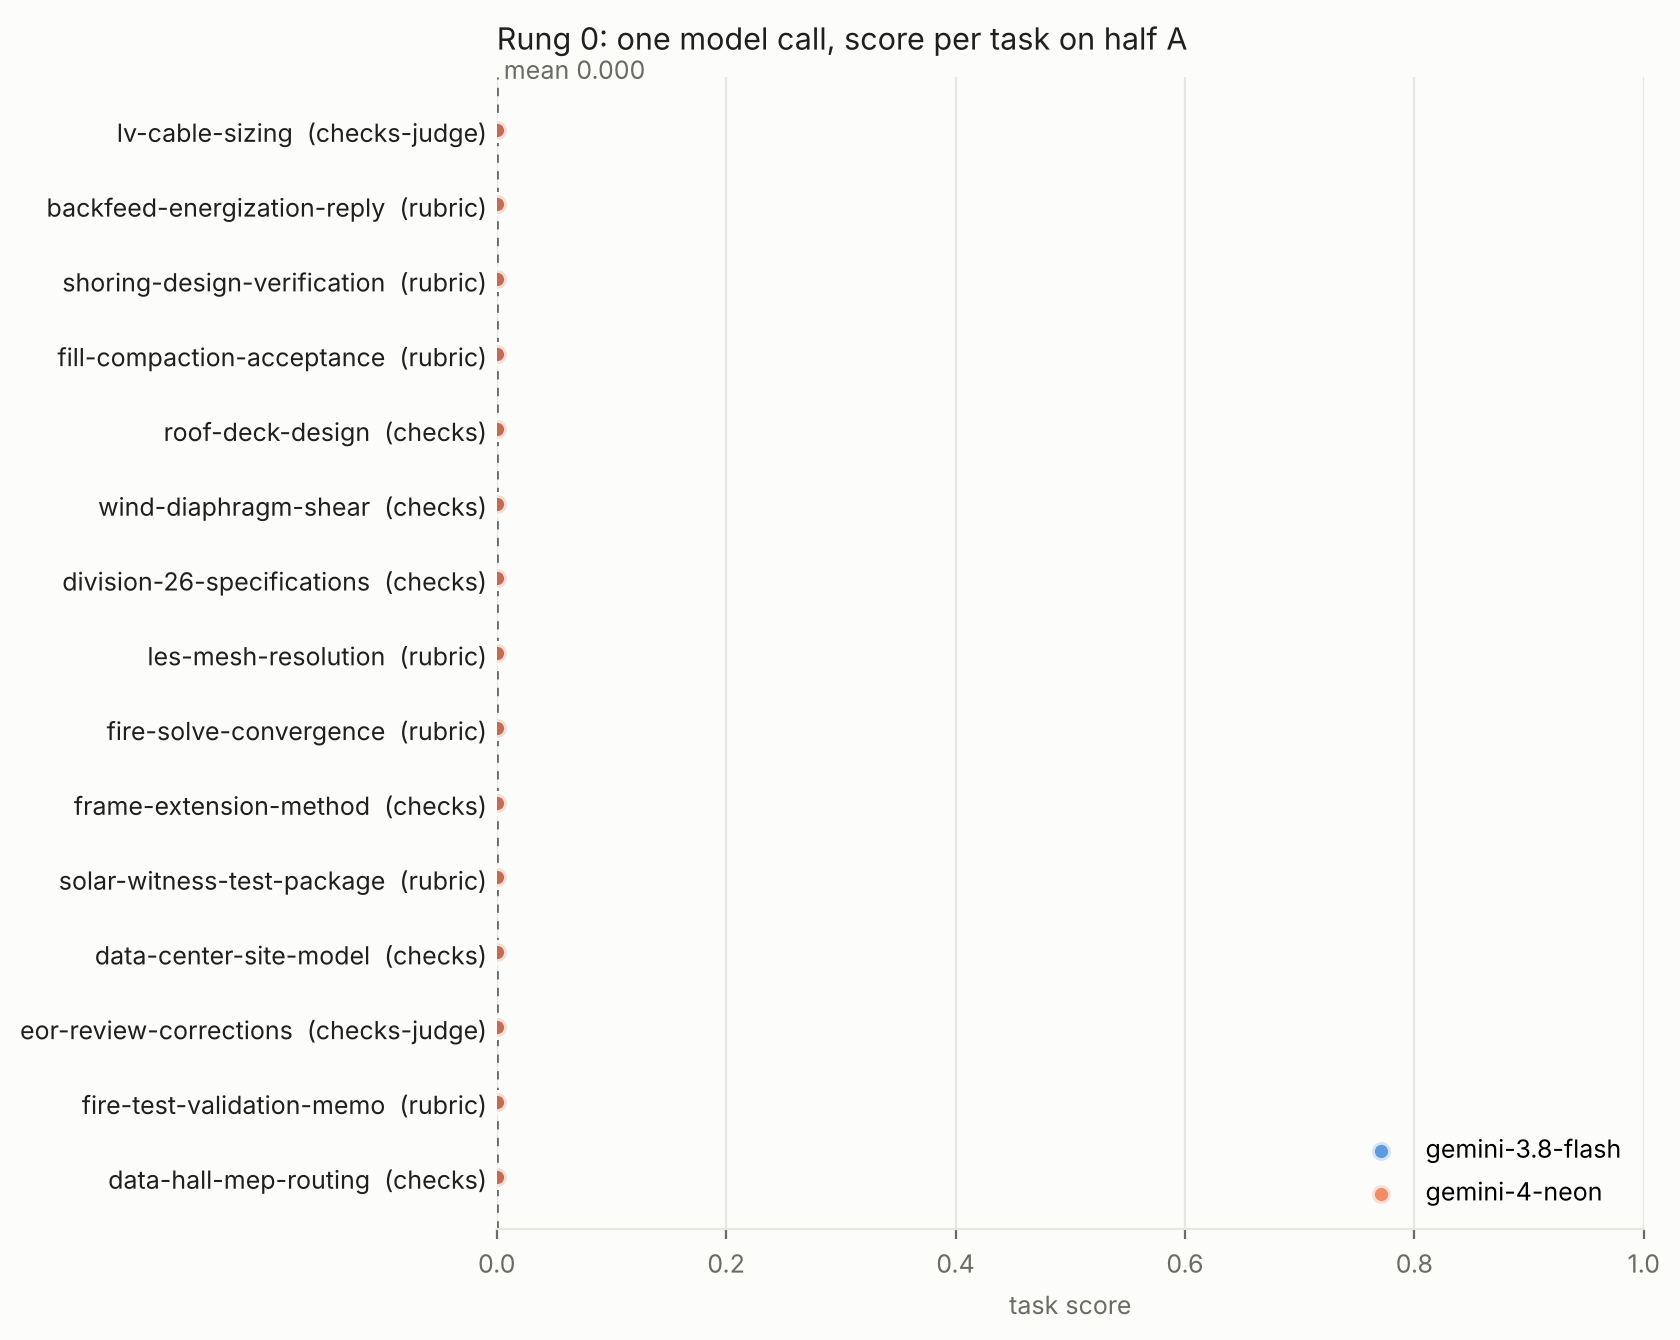

    run                                                                                              label                         model half         judge  score valid measured   run date
run-001                                        rung 0: single model call, files as text (gemini-3.8-flash) google-cloud/gemini-3.8-flash    A gemini-4-neon  0.007    NO    15/15 2026-11-26
run-002                                           rung 0: single model call, files as text (gemini-4-neon)    google-cloud/gemini-4-neon    A gemini-4-neon  0.000    NO    15/15 2026-11-26
run-003                     rung 0 v2: single model call, files as text, 64k output cap (gemini-3.8-flash) google-cloud/gemini-3.8-flash    A gemini-4-neon  0.000    NO     1/15 2026-11-26
run-004                        rung 0 v2: single model call, files as text, 64k output cap (gemini-4-neon)    google-cloud/gemini-4-neon    A gemini-4-neon  0.000    NO     1/15 2026-11-26
run-005                    rung 0 v3: single model call

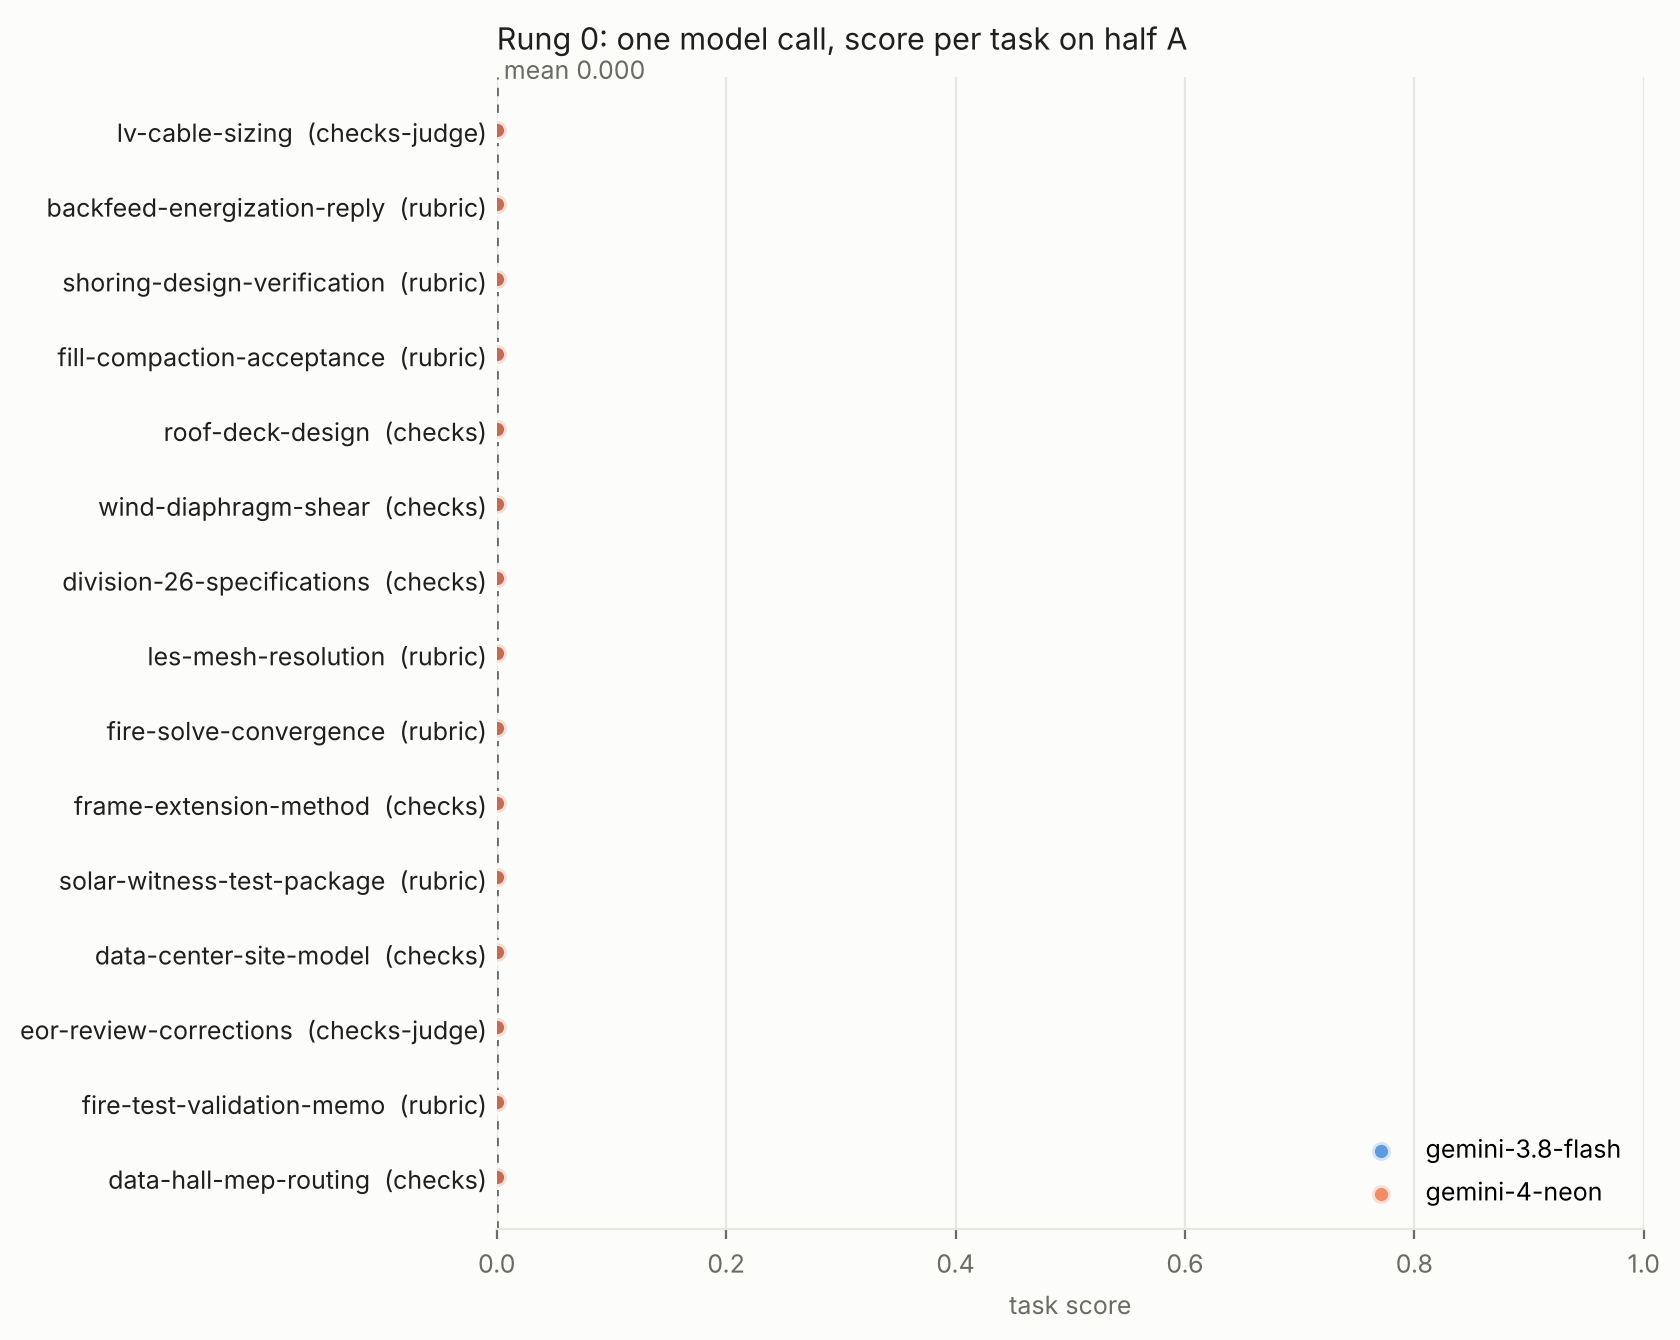

In [5]:
rung0 = [r for r in runs if r["label"].lower().startswith("rung 0") and not tracker.invalid_reason(r)]
if rung0:
    display(plot_runs([r["run_id"] for r in rung0], "Rung 0: one model call, score per task on half A"))
    print(overview[overview["label"].str.lower().str.startswith("rung 0")].to_string(index=False))
else:
    print("No rung-0 run is recorded yet.")

### Where the full outputs live, and how we count effort

* **Summary** of every run (scores, per-task seconds and tokens, grader notes): `research/runs.jsonl`,
  in git, small.
* **Everything else** (agent trajectories, serve logs, grader output, produced files): the
  Cloud Storage bucket `gs://ple-runs-<project number>/runs/`, synced from the VM after each run
  by `infra/gcp-vm/save_runs.sh`. The "engineering reasoning" walk-through is written from these.
* **Effort is counted in model calls, tokens and runtime, not dollars.** A *call* is one request
  the harness sends to the model endpoint. The harness counts them itself and writes one
  `CALLS {...}` line per task: successful calls, failed calls (errors and streams that ended
  early), and tokens as the endpoint reports them: input (of which **cached**, served from the
  provider's prompt/KV cache) and output (of which **reasoning**). Every retry is its own call
  and the SDK's hidden retries are switched off. The raw `usage` object of each call is logged
  too (`USAGE {...}`), so the figures can be checked against what the endpoint said. Two limits:
  a failed call's tokens are invisible to us, and whether the evaluator's own `tokens` figure
  counts cached tokens inside input or beside it is still to be verified against these lines.
  Our own cache estimate: each call also logs hashes of its prompt prefix (never the text), and
  `research/kvcache.py` replays the calls through a simulated prefix cache (longest shared prefix
  with an earlier call of the same model within a time window, above a minimum size) to split
  input tokens into cached and uncached. The window and minimum are provider-specific and not
  known to us: they are placeholders until calibrated against the endpoint's reported cached
  tokens, and `kvcache.compare` shows how far off the estimate is.
  Judge calls are made by the grader and are never added in.
  The efficiency plots (score against calls, tokens and runtime) read these numbers.

### Rung 0 v3: the model can see the drawings (run-005, run-006)

Same single call as v2, with the seven PNG sheets attached. **Both still score 0.0, now for a third
reason: the thinking budget.** With the drawings in front of it, the model thinks far longer.

| | Gemini 3.8 Flash | Gemini 4 Neon |
|---|---|---|
| output tokens (thinking) | 63,996 (61,438) | 64,000 (**64,000**) |
| visible answer | thinking text leaking out, no files | none at all |
| files written | 0 | 0 |
| grader | `ERR_NO_SUBMISSION` | `ERR_NO_SUBMISSION` |

Neon spent its entire 64,000-token budget on thinking, so the reply is empty. Flash's reply is its
own working ("Row A: Y = 3000, Row B: Y = 6000, ...": it did read the row positions off the
sheets) cut off before any file. The v2 runs without images thought for 30k tokens; seeing the
drawings roughly doubles it.

Also found: every image was attached **twice** (the extractor scans two overlapping folders), which
doubled the image tokens (18.5k prompt tokens for seven sheets). Fixed in the harness; the v3
token figures are inflated by it.

**Verdict (user decision): v3 is invalid too.** The budget was too small for what the task needs, so
the run measures nothing about the model. v3 is flagged `INVALID` in the tracker.

**The output limit, measured, not assumed.** We probed each endpoint with a trivial request at
increasing `max_completion_tokens` (2026-11-26): **Gemini 3.8 Flash rejects anything above 65,536**
(HTTP 400), while **Gemini 4 Neon accepted every value up to 1,000,000.** So the budget is now per
model (Flash 65,536, its ceiling; Neon 200,000; Gemini 4 Argon stays at 65,536 as the competition
notes say). The duplicate-image bug is fixed too. This is rung 0 v4.

**v4 (run-007, run-008): the budget cannot be raised.** Flash was cut off again (62,914 of 65,532 tokens
spent thinking). Neon was asked for 200,000 tokens and stopped at **exactly 65,536, all of it thinking,
zero text tokens**, with `finish_reason: stop`. The probe only showed that the API *accepts* larger
values for a trivial request, not that the model generates beyond 65,536 (accepted is not honoured).
The effective output ceiling is 65,536 tokens for both models. Both runs are flagged `INVALID`: at the
default reasoning level one call cannot read the drawings and write the script. Seven drawings cost
7,560 image tokens (1,080 each) and the images are now attached once.

**Restart on interruption: built, then scrapped (user decision).** The idea was to call again with the
input and the output so far when a reply is cut off. It does not fit: the model's hidden thinking cannot be
fed back, so for Neon (65,536 tokens of hidden thinking, nothing visible) a restart is just a retry. The
real answer to a fixed output budget is an agent loop, with state in files and a fresh budget per step.
For rung 0 the next try is simpler: **a low reasoning effort** (v5, single call, nothing else changed).

### Rung 0 v5: low reasoning effort, the first valid result (run-009, run-010)

Same single call, images attached once, reasoning effort **low**. Both models now write a script and
the grader runs it.

| | Gemini 3.8 Flash | Gemini 4 Neon |
|---|---|---|
| output tokens (thinking) | 11,506 (0) | 25,954 (14,730) |
| files written | `solution.py`, `reconciliation.json` | `solution.py`, `reconciliation.json` |
| grader | `ERR_EXEC`: the delivered script failed when the grader ran it | valid model; **connectivity gate passed**, **clash gate failed** |
| the failure | `pset.edit_pset(product=...)`: no such argument (an ifcopenshell API mistake) | 30 hard clashes, 8.5 % rule violations, route 402 m against an optimum of 261 m |
| score | 0.0 | 0.0 |

Reading the drawings worked: Neon's design connects every service to the entry that its first,
blind attempt missed. What is left are the failures a person finds by *running* the work: Flash's
script dies on its first execution, and Neon's clashes show up as soon as a clash check is run on its
own model. Neither model could run anything in this design. That is the evidence for rung 1: a loop in
which the model runs its script and the checks the grader will apply, and fixes what they show.

**What this says.** In one call, at the default (highest) reasoning level, a task that needs
seven drawings read and a 400-line script written does not fit in a 64,000-token output budget.
The reasoning level is therefore a design knob to measure (low / medium / high), not a constant.

### The score is not enough: every check, one by one

The grader runs many checks and a single failed *gate* zeroes the score, so the score hides the rest.
`research/check_table.py` lists every check of a trial next to the score. Below: the blind v2 attempt
(run-004), Flash at low effort (run-009, its delivered script failed when run, so no check ran) and Neon at low effort (run-010).

In [6]:
import check_table
from IPython.display import Markdown, display
for rid in ("run-004", "run-009", "run-010"):
    display(Markdown(check_table.table(rid)))

**run-004** · score 0.0 · exec_status ERR_CLASH

| Check | Result | Detail |
|---|---|---|
| Script ran and wrote the model | pass | valid=1.0, 3.8 s |
| Gate 0: IFC4 schema / modelling contract | pass | 0 errors |
| Gate 1: no hard clash (> 2 mm) | FAIL | 5 clashes of 241 checkable pairs: 4 background x background (the model's own rebuild); 1 service x background |
| Gate 2: connectivity / row coverage | FAIL | 6 rows, min coverage 0.0 (needs 0.8), 20/22 cooling units reached; NOT FED: cable_tray: nothing within 2500mm of the service entry at (200, 3360) — the network is not fed; busway: nothing within 2500mm of the service entry at (200, 3360) — the network is not fed; chw_pipe: no |
| Rule: clear_height (>= 2600 mm) | FAIL | 12 violations in 85 items checked; e.g. underside at 2120mm above finished floor, needs 2600mm (TIA-942 5.3.4.3 / TIA-942-B-2017 6.4.2.4) |
| Rule: sprinkler_clearance (>= 460 mm) | pass | 0 violations in 60 items checked |
| Rule: sprinkler_obstruction_offset (3x the obstruction, capped at 610 mm, within 450 mm below the deflector) | pass | 0 violations in 60 items checked |
| Rule: wide_obstruction_needs_sprinkler (a head beneath any obstruction wider than 1200 mm) | NOT PASSED | nothing was checked: the model has nothing this rule applies to. The grader lets it through, but compliance is not shown, so it counts as not passed |
| Rule: tray_stack_headroom (>= 300 mm between stacked runs) | FAIL | 5 violations in 27 items checked; e.g. 171mm of access below CHW-CA1-W (1cnbU39RfPPvQcC_VlQS99), needs 300mm (ANSI/TIA-569-B, cited in ANSI/TIA-942 7 |
| Rule: tray_below_tile (>= 20 mm) | NOT PASSED | nothing was checked: the model has nothing this rule applies to. The grader lets it through, but compliance is not shown, so it counts as not passed |
| Rule: pdu_dedicated_space (no foreign piping within 1800 mm above a PDU) | pass | 0 violations in 4 items checked |
| Rule: power_telecom_separation (>= 300 mm on at least one axis) | pass | 0 violations in 5 items checked |
| Efficiency: route length vs reference | info | 265.4 m against 260.6 m (factor 0.982) |

**Compliance tally: 5 of 11 passed, 4 failed, 2 not passed (nothing was checked).** A check that tested nothing does not show compliance.

Score formula: compliance 0.929 (= 1 - 0.071) x efficiency 0.982 = **0.913** if every gate had passed; the failed gates make it **0.0**.

**run-009** · score 0.0 · exec_status ERR_EXEC

| Check | Result | Detail |
|---|---|---|
| Script ran and wrote the model | FAIL | ERR_EXEC: raise TypeError(msg) from e / TypeError: Incorrect function arguments provided for pset.edit_pset |

**Compliance tally: 0 of 0 passed, 0 failed, 0 not passed (nothing was checked).** A check that tested nothing does not show compliance.

**run-010** · score 0.0 · exec_status ERR_CLASH

| Check | Result | Detail |
|---|---|---|
| Script ran and wrote the model | pass | valid=1.0, 1.7 s |
| Gate 0: IFC4 schema / modelling contract | pass | 0 errors |
| Gate 1: no hard clash (> 2 mm) | FAIL | 30 clashes of 282 checkable pairs: 8 chilled water segment x chilled water segment (same service); 8 background x background (the model's own rebuild); 7 busway segment x busway segment (same service); 7 cable tray segment x cable tray segment (same service) |
| Gate 2: connectivity / row coverage | pass | 6 rows, min coverage 0.983 (needs 0.8), 22/22 cooling units reached |
| Rule: clear_height (>= 2600 mm) | FAIL | 16 violations in 85 items checked; e.g. underside at 1890mm above finished floor, needs 2600mm (TIA-942 5.3.4.3 / TIA-942-B-2017 6.4.2.4) |
| Rule: sprinkler_clearance (>= 460 mm) | pass | 0 violations in 79 items checked |
| Rule: sprinkler_obstruction_offset (3x the obstruction, capped at 610 mm, within 450 mm below the deflector) | pass | 0 violations in 79 items checked |
| Rule: wide_obstruction_needs_sprinkler (a head beneath any obstruction wider than 1200 mm) | NOT PASSED | nothing was checked: the model has nothing this rule applies to. The grader lets it through, but compliance is not shown, so it counts as not passed |
| Rule: tray_stack_headroom (>= 300 mm between stacked runs) | FAIL | 8 violations in 25 items checked; e.g. 166mm of access below CT-SEG-01 (2ygLfHVBH8jQq9hvt1uPGM), needs 300mm (ANSI/TIA-569-B, cited in ANSI/TIA-942 7 |
| Rule: tray_below_tile (>= 20 mm) | NOT PASSED | nothing was checked: the model has nothing this rule applies to. The grader lets it through, but compliance is not shown, so it counts as not passed |
| Rule: pdu_dedicated_space (no foreign piping within 1800 mm above a PDU) | pass | 0 violations in 6 items checked |
| Rule: power_telecom_separation (>= 300 mm on at least one axis) | pass | 0 violations in 8 items checked |
| Efficiency: route length vs reference | info | 402.0 m against 260.6 m (factor 0.648) |

**Compliance tally: 6 of 11 passed, 3 failed, 2 not passed (nothing was checked).** A check that tested nothing does not show compliance.

Score formula: compliance 0.915 (= 1 - 0.085) x efficiency 0.648 = **0.593** if every gate had passed; the failed gates make it **0.0**.

**Reading run-010 (Neon, low effort, images), check by check**

* **Passed:** the script runs, the IFC4 contract (gate 0), and **connectivity (gate 2)**: all 6 rows
  served at 98 % or better and all 22 cooling units reached. This is the effect of seeing the drawings:
  the blind run (run-004) was not connected to the entry at all.
* **Failed gate 1, 30 clashes, in two groups.** **22 are segments of the same service overlapping where
  they join** (8 chilled water, 7 busway, 7 cable tray): the same defect the official template's near
  miss had. **8 are the model's own background rebuild** clashing with itself (for example the
  containment roof against its door). One generic check, "no two pieces of a route overlap by more than
  2 mm", would remove 22 of the 30.
* **Failed two compliance rules, both from the rebuild, not the routing.** 16 sprinkler heads sit at
  1,890 mm above the floor where 2,600 mm is needed (an elevation misread), and 8 cable-tray runs leave
  only 166 mm of access underneath where 300 mm is needed.
* **Efficiency:** the route is 402 m against a 261 m reference (factor 0.648, 54 % too long).
* **Two rules checked nothing, and count as NOT PASSED** (`wide_obstruction_needs_sprinkler`,
  `tray_below_tile`: 0 items checked, in this run and in the blind one). The grader lets a rule through when
  the submitted model has nothing it applies to, but a compliance check that tested nothing does not show
  compliance, so we count it as not passed. Run-010's tally is **6 of 11 passed, 3 failed, 2 not passed**.
  **Why they checked nothing (from the task's own drawings, 2026-11-27).** Both rules are defined on the
  sheets, and the model built both elements to those definitions. Sheet A-301 says the top of any under-floor
  tray must be 20 mm or more below the underside of the floor panel, and that the access floor is one 35 mm
  panel following the room outline (not tiles): the script's floor is exactly that, and its tray top sits 88
  mm below the panel. Sheets F-101 and A-602 say the 1,400 mm cold-aisle containment roof is a fixed
  obstruction wider than 1,200 mm that needs heads beneath it: the script's four roofs are 1,400 mm wide and
  it has the 16 in-aisle heads. Yet the grader found nothing to check for either rule, although it did see
  the roofs for the clash gate. **None of the seven sheets, and not the task text, names the IFC class,
  type or property that identifies a floor panel or a containment roof** (every sheet answered "none" when
  asked for IFC class, ObjectType or property-set names; the task text only says "exact element classes" and
  gives one example, racks). So the likely cause is a hidden naming convention: the grader recognises these two
  elements by names the task never states. This is a likelihood, not proven; the grader's own files would
  show it and we do not open them.
* **If every gate had passed, the score would have been 0.593** (compliance 0.915 x efficiency 0.648).
  That is the real distance to a usable answer.

Neither the 22 same-service overlaps nor the sprinkler height needed engineering judgement to find: a
script that checks its own model finds them.

In [7]:
import costs
usage = pd.DataFrame([{"run": r["run_id"], "model": r["harness"]["model"], **costs.run_usage(r)} for r in runs])
usage

,run,model,tasks,calls,input_tokens,output_tokens,task_hours,longest_min
0,run-000,google-cloud/claude-opus-5-5,0,NaN,0,0,0.00,0.0
1,run-001,google-cloud/gemini-3.8-flash,15,NaN,2506110,478038,0.96,5.0
2,run-002,google-cloud/gemini-4-neon,15,NaN,2473647,449884,1.25,8.8
3,run-003,google-cloud/gemini-3.8-flash,1,1.0,2800,63996,0.10,5.8
4,run-004,google-cloud/gemini-4-neon,1,1.0,2817,49290,0.11,6.5
5,run-005,google-cloud/gemini-3.8-flash,1,1.0,18466,63996,0.12,6.9
6,run-006,google-cloud/gemini-4-neon,1,1.0,18511,64000,0.14,8.6
7,run-007,google-cloud/gemini-3.8-flash,1,1.0,10043,65532,0.10,6.2
8,run-008,google-cloud/gemini-4-neon,1,1.0,10076,65536,0.15,9.2
9,run-009,google-cloud/gemini-3.8-flash,1,1.0,10043,11506,0.02,1.2


### Rung 0 v2, one task: `data-hall-mep-routing`

To start simple we ran both models on a single task, a checks-graded one (no LLM judge involved).
Both scored **0.0**, for different reasons, and the grader's own report says exactly why.

| | Gemini 3.8 Flash | Gemini 4 Neon |
|---|---|---|
| output tokens (of which thinking) | 63,996 (60,587) | 49,290 (29,597) |
| why the call ended | hit the 64,000-token cap | finished |
| what was written | a script cut off mid-file | a 48 KB script and a reconciliation file |
| grader verdict | `ERR_NO_OUTPUT`: the script wrote no file | `ERR_CLASH`: valid design, but two hard gates failed |

**What the trial folders show once read in full.** This task's only inputs are **seven PNG drawing
sheets**, and rung 0 lists images by name only (`image: not included as text`). Neither model
saw a drawing. Neon said so in its final message ("all seven required drawing sheets were omitted
in this text-only environment") and wrote a template with provisional placeholders for everything
that comes from the drawings: hall dimensions, column grid, entry points, sprinkler positions. The
grader's two failed gates are consequences of that: the service entry at (200, 3360) exists only
on sheets M-101/E-101, and a guessed layout cannot connect to it or clear unseen clashes.

So the 0.0 on this task measures **missing inputs, not engineering ability**. Flash's cut-off
(thinking used 60,587 of 63,996 tokens) is a second, separate fault. Two lessons for the ladder:
rung 0 as built is blind on every task whose inputs are images, so it cannot serve as a floor
for those; and the first capability to add is *seeing the inputs*, before any run-and-check
loop. (Our first note here said the missing piece was a run-and-check loop; reading the
trajectory showed that was premature, and it is kept in the lab log as a correction.)

### Rung 0 findings (run-009 to run-016: 8 observations, 4 per model, one task)

**Headline: a single call never produced a model that passes the gates. All 8 observations scored 0.0, and
four different things stopped them.** One task (`data-hall-mep-routing`), one call, files and the seven drawing
sheets attached, reasoning effort low, judge Gemini 4 Neon. Each run is one trial; the label says repeat n.

| Model | Calls | Input tokens | Output tokens | Time | What the grader found, per observation |
|---|---|---|---|---|---|
| Gemini 3.8 Flash | 1 | 10,043 | 11,404 to 13,809 | about 1.3 min | script failed to run (3), clash gate failed (1) |
| Gemini 4 Neon | 1 | 10,076 | 25,066 to 50,422 | 3.6 to 5.2 min | clash gate failed (2), invalid IFC (2) |

**What the failures are**

1. **The delivered script does not run (3 of 8, all Flash).** The agent did not crash: it finished and
   delivered `output/solution.py`, and the grader's run of that file failed within one second on a wrong
   ifcopenshell call: `pset.edit_pset(product=...)` (no such argument), `aggregate.assign_object(product=...)`
   (the argument is `products`), and `col_shape.Representations[0]` (no such attribute). For two of these,
   ifcopenshell's own message prints the correct signature: one run of the script would have shown it.
2. **The script runs but writes an invalid IFC file (2 of 8, both Neon).** The grader reports 7 to 8 schema
   violations (for example 6 shape representations where exactly 1 is allowed).
3. **Valid model, clash gate fails (3 of 8).** Only here do the compliance rules run. Two of the rules checked
   nothing in any of these runs (`wide_obstruction_needs_sprinkler`, `tray_below_tile`), so we count them not
   passed. Of the rules that did run, `clear_height` and `tray_stack_headroom` failed every time. Had the gates
   passed, the two runs we read would have scored 0.538 (Flash) and 0.612 (Neon), mostly route length:
   425 m and 389 m against 261 m.
4. **Nothing in the run can tell the model any of this.** One call has no way to execute what it wrote.

**Reading it.** The weak point is not understanding the task: a model that gets through the gates scores about
0.5 to 0.6 before any rule fix. It is that the deliverable is a program the model wrote blind. Cost is small and
exact: one call, about 10,000 input tokens, 11,000 to 50,000 output tokens. Effort at low cut Neon's output from
65,536 tokens (all spent thinking) to about 25,000.

**What we deliberately did not do.** We did not add a run-and-check step to rung 0; that would no longer be a
single call. Running the delivered file, and validating the model it writes with ifcopenshell, are recorded as
requirements for a later rung (design-decisions: Run the deliverable). Rung 1 does not include them.

## 5. A reference point, and what it taught us

### The official template on half A

The competition's starter repository ships a complete dev run of the Pi coding agent on Claude
Opus 5.5. We did not build it; we record it as a reference for what a capable general-purpose
coding agent scores on our half A.

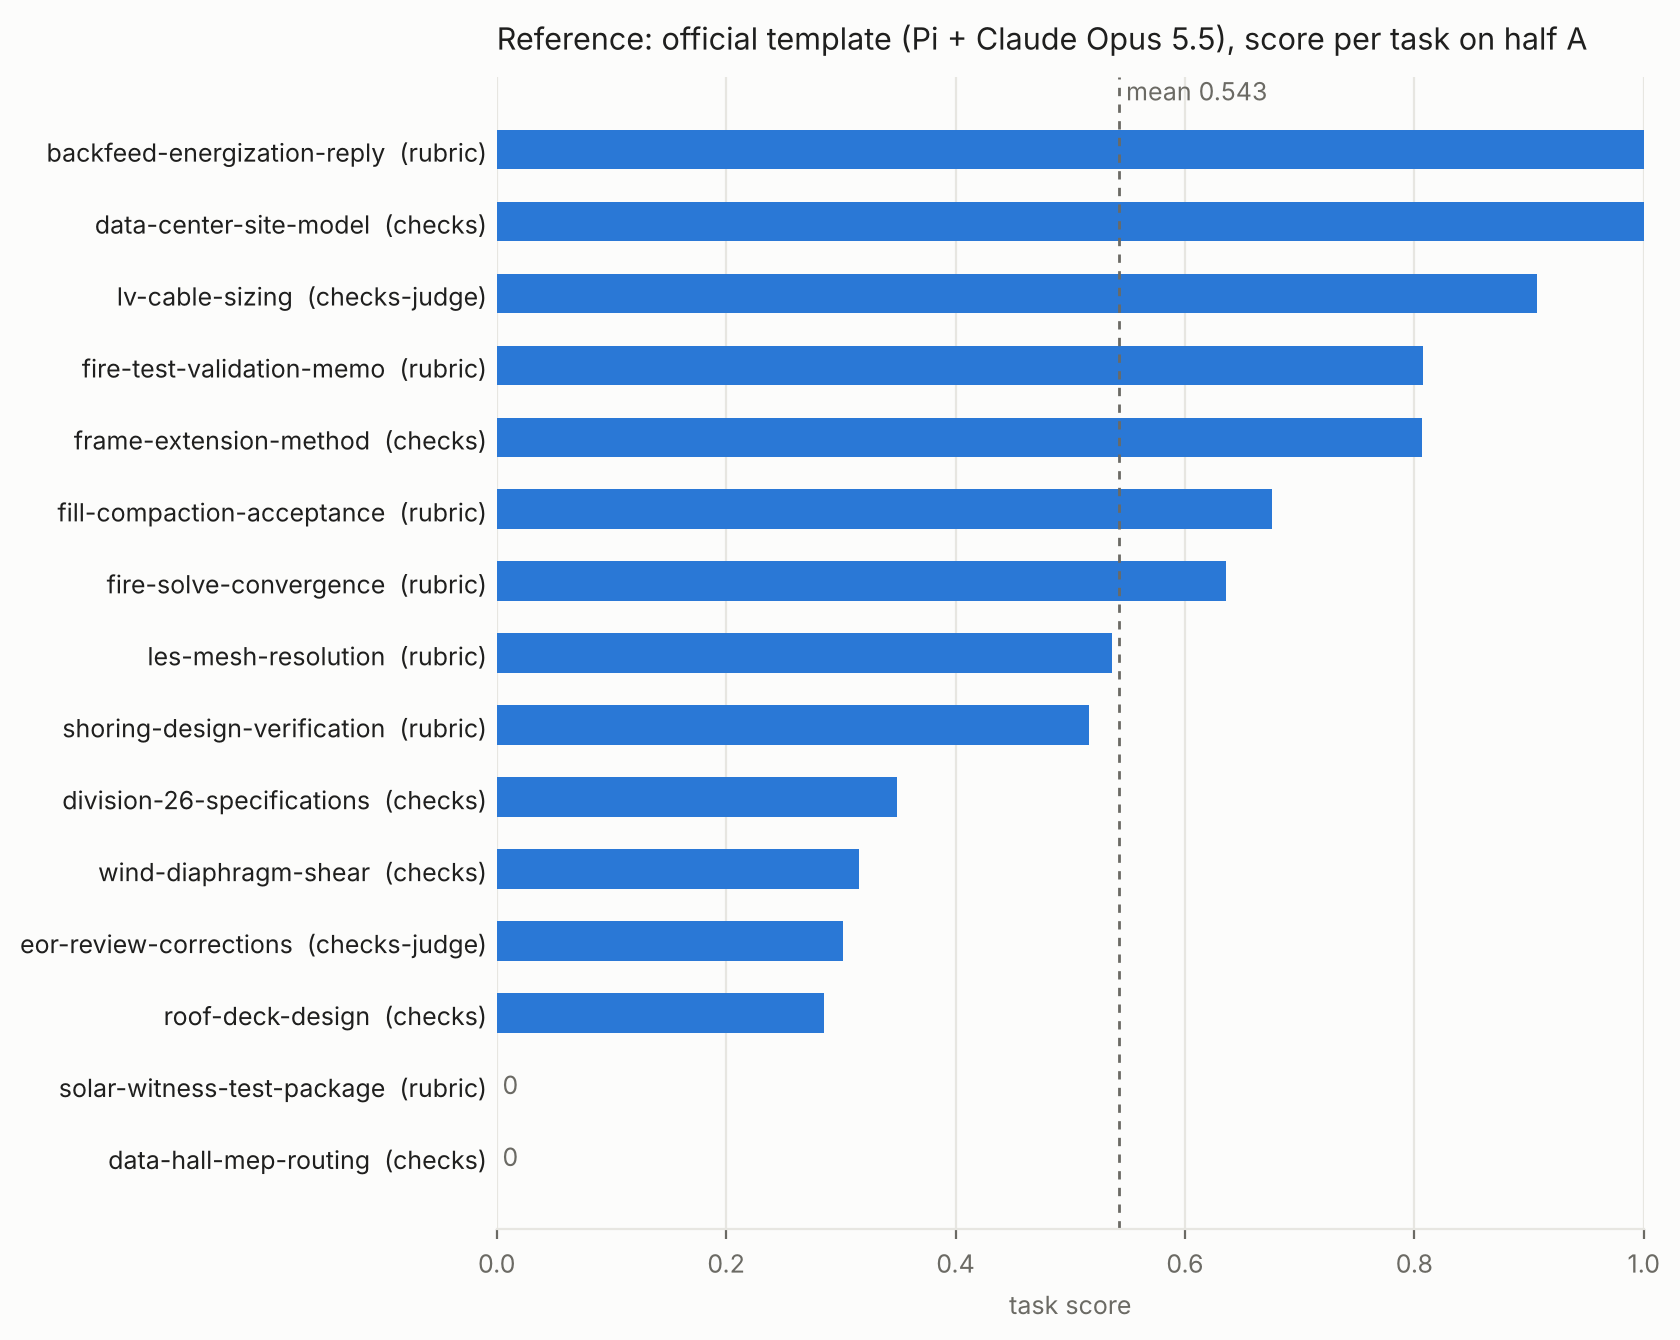

In [8]:
reference = runs[0]
plot_runs([reference["run_id"]], "Reference: official template (Pi + Claude Opus 5.5), score per task on half A");

In [9]:
f = task_frame(reference)
f.groupby("grading")["score"].agg(["mean", "count"]).round(3)

,mean,count
grading,,
checks,0.460,6
checks-judge,0.604,2
rubric,0.596,7


**What stands out**

* A wide spread: two tasks score `1.0`, two score `0`.
* The three structural calculation tasks (wind diaphragm, roof deck, and the EOR corrections)
  all sit around `0.3`.
* One of the zeros, `data-hall-mep-routing`, is a near miss, below.

### A near miss that scored zero

`data-hall-mep-routing` asks for a Python script that builds a clash-free 3D model (IFC) of a data
hall from seven drawing sheets and routes cable tray, busway and chilled-water pipe through it.

We re-graded the template's own deliverable with the task's public grader:

| | template's design | reference route |
|---|---|---|
| connectivity (every row served, every cooling unit reached) | passed | passed |
| total route length | 186.9 m | 260.6 m |
| code-rule violation rate | 8 % | 0 % |
| clashes over 2 mm | **23** | 0 |
| **score** | **0** | 1 |

Every one of the 23 clashes is between two segments **of the same service** overlapping where
they join. Without them the design would have scored about **0.92**. One generic check (no two
solids overlap by more than 2 mm, including pieces of the same route), run before finishing, would
have caught it.

This is the pattern our harness is built around: **the agent defines how its work will be
judged, checks its work against that before finishing, and fixes what fails.**

## 6. The ladder: build up from the floor

We add one capability at a time, each motivated by a failure we observe, measuring every step on
half A.

| Rung | Harness | Question it answers |
|---|---|---|
| 0 | **one model call**: files pasted in as plain text, deliverables written from the reply | how far does one careful read of the project get? |
| 1 | Pi agent loop; files fed as context (not read by tool); write, edit, bash; a review-your-work instruction; no structured checks, no ifcopenshell | how much does a loop that can look at its own work add? |
| 2 | rung 1 with the data out of the first message, a `read` tool, a requirements-then-checks method | does a method help? |
| 3 | rung 2 plus ifcopenshell, and an evaluation engine the agent programs (`set_checks`, `evaluate`, `optimize`, `verify_facts`) | what can a tool supply that the agent will not write for itself? |
| ... | each next capability is chosen from what rung *n* got wrong | |

Rung 1 is chosen after we have read rung 0's failures task by task.

### 6a. Rung 1: the model starts writing its own checks, and gets one wrong

**We never asked for self-checks. Rung 1 only gave the model tools and a note to review its work. Both models
wrote their own checks anyway, and the check that mattered used the wrong definition.** (One run per model, task
`data-hall-mep-routing`, rung 1 v1; keyword counts over the agents' commands.)

| | Gemini 3.8 Flash (run-017) | Gemini 4 Neon (run-019) |
|---|---|---|
| commands the agent ran | 295 | 21 |
| schema validation of its own model (`ifcopenshell.validate`) | 6 | 3 |
| pairwise geometry clash checks | 10 | 2 |
| of those, checks that skip pairs of the same service | 4 | 2 |
| first clash check (step of its run) | 245 of 295 | 19 of 21 |

What it got right: schema validation (the grader's schema gate passed in both runs), and Neon's first clash check
found 8 overlaps in its own room rebuild, which the final model does not have (rung 0 had 2 to 10 such overlaps in
every run).

What it got wrong: both clash checks skipped same-service pairs, with a comment saying why (Neon: *they meet at
tees/elbows*; Flash: *don't check elements of same service network*). The task defines a hard clash as one solid
overlapping another by more than 2 mm **anywhere**, and the grader reports 22 same-service overlaps in both runs,
the only gate that failed. The check agreed with the model's belief, not with the task.

**Why this matters for the write-up.**
1. **The behaviour is real and appears with the loop, not before.** Rung 0 (one call, no tools) had no chance to
   check anything; with tools both models started verifying their output without being told.
2. **A self-check is only as good as the definition it encodes.** A check built from the model's own reading of
   the requirement can pass while the requirement fails. More checking is not enough; the check has to come from
   the requirement as written.
3. **It motivates the next rung** (structured self-check against the task's own words) with a failure we
   observed, rather than a guess. Whether it works is for the next measurement; one run per model so far.

### 6b. Rungs 1 and 2: a loop and a method, and the clash gate still fails

Neon, one task (`data-hall-mep-routing`), valid runs only (the agent could not run ifcopenshell in rung 1 v4 and
rung 2 v2 and v3: a stub shadowed the library so the loop had to rely on its own checks; the later rungs lift that).
The table is generated from the run tracker (`research/rung_summary.py`).

In [10]:
import sys
sys.path.insert(0, str(HERE))
import rung_summary
from IPython.display import Markdown
Markdown(rung_summary.table("gemini-4-neon"))

| Version | ifcopenshell for the agent | runs | passed the gates | mean score | how the others failed | calls (mean) | prompt tokens (mean) | new, uncached (mean) | minutes (mean) |
|---|---|---|---|---|---|---|---|---|---|
| rung 0 v5 | no tools | 4 | 0 of 4 | 0.000 | ERR_CLASH 2, ERR_VALIDATE 2 | 1.0 | 10,076 | 8,110 | 4.1 |
| rung 1 v1 | yes | 1 | 0 of 1 | 0.000 | ERR_CLASH 1 | 10.0 | 335,329 | 97,606 | 9.4 |
| rung 1 v3 | yes | 1 | 0 of 1 | 0.000 | ERR_CLASH 1 | 10.0 | 338,103 | 63,010 | 7.3 |
| rung 2 v1 | yes | 1 | 0 of 1 | 0.000 | ERR_CLASH 1 | 12.0 | 336,957 | 59,276 | 6.7 |
| rung 1 v4 | no (blocked) | 6 | 2 of 6 | 0.256 | ERR_CLASH 2, ERR_VALIDATE 2 | 8.0 | 302,152 | 66,213 | 6.1 |
| rung 2 v2 | no (blocked) | 6 | 0 of 6 | 0.000 | ERR_CLASH 6 | 9.0 | 275,577 | 55,826 | 6.6 |
| rung 2 v3 | no (blocked) | 6 | 0 of 6 | 0.000 | ERR_CLASH 6 | 8.7 | 261,542 | 63,115 | 8.3 |
| rung 3 v1 | yes + engine | 1 | 0 of 1 | 0.000 | ERR_CONNECTIVITY 1 | 10.0 | 410,387 | 89,741 | 8.2 |
| rung 3 v2 | yes + engine | 3 | 3 of 3 | 0.928 | - | 9.3 | 341,966 | 61,923 | 7.8 |
| rung 3 v3 | yes + engine | 3 | 3 of 3 | 0.923 | - | 11.3 | 428,269 | 114,105 | 8.0 |
| rung 3 v4 | yes + engine | 3 | 1 of 3 | 0.308 | ERR_CONNECTIVITY 2 | 11.7 | 477,514 | 177,568 | 9.6 |

**What the six-run groups show.** Rung 1 v4 passes the gates in 2 of 6 runs (0.921 and 0.612), rung 2 v2 and v3 in
0 of 6, and every failure is the clash gate. A loop, a read tool and a method did not move the result. We read all 18
runs (`docs/failure-analysis.md`) against four hypotheses:

| Hypothesis | Verdict | Main evidence |
|---|---|---|
| The agent misreads the drawings | **Not the main cause** | 12 data notes share a 70-number consensus; position-dependent gates passed in every run that reached them |
| It turns a requirement into the wrong check | **Partly, at one step: what a requirement applies to** | all 20 requirement groups are in every list; "no overlap anywhere" became checks on the pairs the agent had designed for, "2600 mm headroom" became a test of routes only |
| The checks are not designed well enough | **Yes, the main cause** | 9 of 12 rung 2 checks passed the first time they ran; they exclude the pairs that are wrong, so they cannot fail on the real defect |
| It fails to adapt to feedback | **No, with one caveat** | every real failure was followed by a fix and a re-run; but the first all-pass ends the work (8 to 10 of 40 calls used) |

**The central observation.** The same belief ("pieces of one run meet at joints, so they overlap there") shapes the design
and the check, so the two never disagree. In 12 of 12 rung 2 runs the check excluded same-service pairs. One added
sentence in the prompt ("check every item or pair, nothing excluded, say what you left out") completed the background
sweeps and left the same-service exclusion untouched in 6 of 6. **An instruction can fix a check's scope; it cannot fix
the belief behind it.** That is what a tool has to supply.

### 6c. The engine: what we can provide that an agent will not write for itself

Agents already write checks unprompted, so a check library alone adds little. What an agent does not produce on its own is
(1) **semantics validated against the grader**, (2) **diagnosis**, (3) **a report of what its checks leave out**, and (4) **an
independent test of the check itself**. We built an evaluation engine (`harnesses/pi-rung3/engine.py`, tested) around those:

* **Strict by default and validated.** `no_overlap` examines every pair of the selected items; excluding pairs is an
  explicit rule, and the report counts pairs examined and excluded and measures the overlaps *inside* the excluded
  group. On the 12 delivered models we could rebuild, the engine's clash pairs equal the grader's pair for pair
  (`research/engine_vs_grader.py`).
* **Diagnosis, not a count.** Overlaps are clustered by cause and each cause gets the exact fix ("end X at x = 664
  instead of 600: shorten by 64 mm so it butts against Y"): 22 overlaps became 5 causes on a real failing model. Every
  other check reports where, by how much, and the move that fixes it, plus its **margin** (slack to its limit).
* **Scope facts and scope shadows.** Which check types test each kind of element; kinds tested only for overlap; and
  for a height check, the elements *outside* its roles that would break the same limit (not counted, but shown).
* **Probes.** Each check is run on a tiny synthetic model with a planted fault and a clean case; a check that cannot
  fail its own fault is flagged before the design is judged by it. A check that examines nothing is an error, not a pass.
* **IFC schema messages.** The validator's express-rule output is translated into what to change (for example "one
  shape representation shared by 79 products: create one per product").
* **Tools around it:** `set_checks` (the agent programs the engine and may rewrite it), `evaluate` (build, validate,
  run), `optimize` (a seeded search over the script's parameters, no model calls inside the loop) and `verify_facts`
  (a fresh second reader answers the same questions from the files; answers withheld).

![What we provide](../docs/figures/fig5-structured-architecture.png)

### 6d. Rung 3, version by version: what each run taught us

Neon, one task. Scores from the tracker; "gates" means the grader's schema, clash and connectivity gates.

| Version | Change (one at a time where possible) | Runs and scores | What it showed |
|---|---|---|---|
| v1 | a separate check-builder agent writes the checks from the task text; the designer builds against them | run-046 0.925 (**invalid**), run-047 0.000 | run-046: the engine never ran (below). run-047: three custom checks crashed, the service-entry coordinates live only in the drawings the check-builder never saw, and the row-coverage check measured the wrong thing |
| v2 | **one agent does everything** and may rewrite its checker; ifcopenshell enabled | 0.940, 0.921, 0.923 | all gates pass; every agent read the entry coordinates from the drawings, fixed bugs in its own checks after the probes flagged them, and loosened nothing |
| v3 | instructions on how to read the report; tool results logged | 0.921, 0.923, 0.925 | no change; the agents used spare calls to shorten the route, which the grader's score does not reward here |
| v4 | scope shadows for height checks; the `optimize` tool | 0.925, **0.000, 0.000** | the optimizer drove two designs onto errors in the agent's own checks (below) |
| v5 | binding-check report from `optimize`; `verify_facts`; `bands` in the height check; per-kind scope table | not yet run | targets the v4 failures |

```
run-046 (engine void)  0.925        <- ifcopenshell enabled, the engine's report never reached the agent
v2   0.940 0.921 0.923
v3   0.921 0.923 0.925               <- the same 20 grader violations in every one of these runs
v4   0.925 0.000 0.000
```

In [11]:
rows = []
for r in runs:
    v = tracker.harness_version(r)
    if not v or not v.startswith("rung 3"):
        continue
    t = next(iter(r["tasks"].values()))
    rows.append({"run": r["run_id"], "version": v, "score": round(t["score"], 3),
                 "valid": "NO" if tracker.invalid_reason(r) else "yes",
                 "wall time (s)": t.get("seconds")})
pd.DataFrame(rows)

,run,version,score,valid,wall time (s)
0,run-046,rung 3 v1,0.925,NO,460
1,run-047,rung 3 v1,0.000,yes,493
2,run-048,rung 3 v2,0.940,yes,370
3,run-049,rung 3 v2,0.921,yes,393
4,run-050,rung 3 v2,0.923,yes,640
5,run-051,rung 3 v3,0.921,yes,478
6,run-052,rung 3 v3,0.923,yes,518
7,run-053,rung 3 v3,0.925,yes,444
8,run-054,rung 3 v4,0.925,yes,531
9,run-055,rung 3 v4,0.000,yes,593


**Five findings worth keeping (each from a failure, with the run that showed it).**

1. **The biggest lever was not the engine.** Run-046, where the engine never reached the agent, scored 0.925: inside the
   v2 range (0.921 to 0.940). Rung 2 v3, where ifcopenshell was blocked, passed the gates in 0 of 6. Letting the agent run the
   real library is what moved the result; the engine's own contribution is still to be separated with an ablation (same
   harness, engine off). *We say this because the data say it, not because it is the story we built.*
2. **A tool that fails in the evaluator's environment fails silently for the score.** ifcopenshell's express-rule validator
   imports `pytest`; our test environment had it, the serve environment did not, so `evaluate` crashed on the agent's only call and
   the run was void (run-046, marked invalid, kept). Fixed by pinning the dependency and by making a validator failure
   visible but not fatal. Tests have to run in the environment the build produces.
3. **Agent-written checks encode the agent's beliefs, and the score plateaus where the checks stop looking.** All six
   v2 and v3 runs hit the same two grader rules (`clear_height`: 16 in-aisle sprinkler heads at 1,890 mm against 2,600 mm;
   `tray_stack_headroom`: 4), because each agent scoped its headroom check to the routes. The score is exactly
   1 minus the violation rate (20 of 266 = 0.075), so the compliance gap, not the route length, is what is left. The report
   even said "no kind is uncovered": a clash sweep over everything touches every kind. v4 and v5 changed what the report says
   about scope for that reason.
4. **An optimizer is a faithful amplifier of check error.** In v4 the search shortened the route 4 to 8% in all three runs with
   zero violations at every accepted trial, and two of the three scored 0.000: one had modelled the busway with the wrong IFC
   class (the grader saw no busway), one had the search push the trunks to the edge of its range, 5,000 mm from the grader's
   service entry, which the agent's own checks placed elsewhere. The checks were consistent with the misreading, so no check
   could object. The search found exactly where a check was wrong in the agent's favour. This is the learned-checker version of
   Goodhart's law; v5 answers it with margins (which checks were pushed to their limits), a prompt to re-verify those numbers,
   and an independent second reading of the facts.
5. **The freedom to rewrite the checker went the right way.** In the runs we read (v2 to v4) no rewrite loosened a requirement's
   threshold or dropped a check. The exclusion that 12 of 12 rung 2 agents kept (same-service pairs "meet at joints") was
   *removed by the agent itself* in three of the six v3 and v4 runs (run-053, run-054, run-056): their first configuration had
   it, the probe (a planted overlap between two items of one group) or the strict-sweep rule exposed it, and their final
   messages say they dropped it to check butt-jointed segments strictly. The agent that built the design and the checker that
   judges it no longer shared that belief once a planted fault could contradict it. Every installed version is logged with a
   change list, and each evaluation says what was rewritten since the last, so a loosening would have shown. What the planted
   faults cannot reach is a misreading that the check and the design share (finding 4).

**Engineering reasoning, one concrete case: the sprinkler heads.** A licensed fire-protection or data-centre engineer
reads "2,600 mm minimum headroom" as a requirement on everything in the room that people walk under, and notices that the
drawing sets the in-aisle sprinkler heads at 1,890 mm. That is a conflict between a drawing dimension and a code, and the
engineer resolves it (raise the heads, or document an exception). Our agents read the drawing correctly, built what it said,
and wrote the headroom requirement as a check on pipes and trays, so the conflict never appeared in any report. The failure is
not in perception or arithmetic; it is the engineering step of deciding **what a rule applies to**, which is why the engine now
shows the agent the elements outside a check's scope that would break the same limit.

## Lab log

Dated, honest notes, including what went wrong. Newest last.

* **2026-11-25.** Docker on the Mac is too small, so runs move to a cloud VM. Budget and hard cap
  set up. Claude Opus 5.5 has zero Vertex quota (three increase requests auto-denied), so the dev
  judge is Gemini 4 Neon.
* **2026-11-25.** The Mac broke. A GitHub Actions workflow now drives the VM from a cloud session.
  First attempts failed on small things (a service-account name too short, a lookup that needed
  admin rights).
* **2026-11-26.** The Hugging Face token never reached the VM (it was empty), and two of our own
  checks reported "access OK" when it was not. Replaced with a repository secret and a check that
  tests real access.
* **2026-11-26.** First rung-0 start: the 29-task dataset (16,425 files) downloaded in 28 minutes
  through Hugging Face's rate limit, then the run stopped because the model proxy was not running
  after the VM's reboot. The run script now starts the proxy if it is down.
* **2026-11-26.** Read the judging criteria. Added: a bucket for full run outputs, exact model-call
  counting in the harness (efficiency is judged on calls, tokens and runtime, so no billing
  export), and a write-up tracker keyed to the five criteria.
* **2026-11-26.** Wrote down what every run must record (`docs/run-records.md`) so failures can be
  analysed check by check. Found that the tracker kept only the first grader file per task; it now
  keeps all of them. Found that the competition's proxy retries failed requests itself (3 times),
  so our own call counts are lower bounds; added a request log at the proxy to count what the
  provider actually served, judge calls included.
* **2026-11-26.** Rung 0 v1 finished: Flash 0.007, Neon 0.000. Not a result about the models: the
  32,000-token output cap was reached in nearly every task (thinking tokens count against it) and
  most tasks wrote no file. Kept in the tracker, annotated invalid; reran as v2 with a 64,000 cap
  and finish reasons logged. A lesson for every later rung: **check that the harness's own limits are
  not the thing being measured.**
* **2026-11-26.** Ran rung 0 v2 on one task, both models: 0.0 each. Flash's thinking used 60,587 of
  its 63,996 output tokens and the script was cut off; Neon finished a runnable script that fails
  the clash gate (5 clashes) and the connectivity gate (not connected to the service entry). The
  request log works against the real proxy, and showed that the proxy reports `finish_reason: stop`
  on some calls that spent their whole budget thinking: our cut-off check is only reliable when the
  provider reports `length`, so the harness also needs a token-count check.
* **2026-11-26.** Correction after reading the full trial folders: both models were blind to the
  seven drawing PNGs (images are listed by name only). Neon said so itself and wrote placeholders.
  The "needs run-and-check" conclusion above was premature; rung 0 cannot be a floor on image tasks.
* **2026-11-26.** Decision: **rung 0 is invalid so far.** All four runs (run-001 to run-004) are marked
  invalid in the tracker with the reason; they are kept, not deleted. Rung 0 v3 changes exactly one
  thing: images are attached to the request (the harness reads them and sends them as image parts;
  `NAIVE_IMAGES=0` switches it off for later comparison). Same 64,000-token cap, same reasoning
  effort, same single call.
* **2026-11-26.** Rung 0 v3 (images attached), run-005 and run-006: both 0.0 again. With the
  drawings visible, both models spent the whole 64,000-token budget thinking (Neon: all 64,000 as
  reasoning, empty reply) and wrote no file. Also found that images were attached twice; fixed.
  Next knob to measure: reasoning effort.
* **2026-11-26.** Decision: v3 (run-005, run-006) is **invalid**: the output budget was too small, so
  nothing was written. Probed the endpoints: Flash's hard output limit is 65,536, Neon accepts up to
  1,000,000. Rung 0 v4 uses a per-model budget (Flash 65,536, Neon 200,000) and the image-dedupe fix.
* **2026-11-26.** Rung 0 v4 (run-007, run-008) invalid: the effective output ceiling is 65,536 for
  both models, even though the API accepted 200,000 for Neon (it stopped at exactly 65,536, all
  thinking, no text). The budget cannot be raised; the reasoning level is the remaining lever.
* **2026-11-26.** Decision: do not split into two calls; tried **restart on interruption** (feed the model its
  input and its output so far), implemented it with seven tests, then **scrapped it** the same day: hidden
  thinking can't be fed back, so for Neon it degenerates into a retry. The output ceiling is simply 65,536
  for both Gemini models. Rung 0 v5 = the single call at **low reasoning effort** instead.
* **2026-11-26.** Rung 0 v5 (low effort), run-009 and run-010: **the first valid rung-0 result.** Both
  wrote a script. Flash's delivered script failed when the grader ran it (a wrong ifcopenshell argument); Neon's ran, passed the schema and
  connectivity gates and failed the clash gate (30 clashes). Score 0.0 each, for reasons a run-and-check
  loop would catch. Lowering the effort cut Neon's output from 65,536 hidden-thinking tokens to 25,954.
* **2026-11-27.** Rung 0 v5 repeated three times (run-011 to run-016): all six scored 0.0; with run-009/010, eight observations. Three deliveries (all Flash) failed when the grader ran the script (wrong ifcopenshell arguments, an attribute that does not exist), two were invalid IFC, three had clashes. **The agent did not crash: it finished and delivered a file that does not run.** Trying the file is the first thing an agent must do; the harness must do it too (design-decisions, 'Run the deliverable').
* **2026-11-27.** Rung 1 v1, run-017 (Flash, 287 calls) and run-019 (Neon, 10 calls): both deliver a script that runs and a valid model; both fail the clash gate on the same 22 same-service overlaps. **Both models wrote their own checks unprompted, and both clash checks skipped same-service pairs** (section 6a). Input re-reads by Flash: 10 commands (baseline for the input guard); the v2 job was cancelled when the 20-call budget was decided; v3 runs.
* **2026-11-26.** Looked at the grader's checks one by one (`research/check_table.py`). Neon at low effort:
  schema and connectivity pass; 30 clashes (22 are consecutive segments of the same service overlapping at
  their joints, 8 are the model's own background); 16 sprinkler heads at 1,890 mm (needs 2,600) and 8
  tray runs with 166 mm of access (needs 300); route 54 % too long. Would score 0.593 if the gates passed.
* **2026-11-26.** Process: a job that powers the VM off by itself raced the workflow's own pull and
  lost its results for a while (they were safe on the VM disk and in the bucket). The VM is now
  stopped by the workflow, after the pull.
* **2026-11-26.** Near-loss: syncing the VM's code overwrote its `runs.jsonl`, which held the Neon
  run's record uncommitted. A saved patch let us recover it; the sync now merges records instead
  (`infra/gcp-vm/merge_runs.py`). Lesson: a record that lives only on a machine is not recorded.
* **2026-11-26.** Review of `harnesses/naive` found that a reply cut off at the token limit
  silently lost its last file. Fixed in the harness (the partial file is now written and the cut-off
  is logged); rung 0's first runs predate that fix, which matters only for tasks where the reply
  was cut off.
* **2026-11-27.** Rung 1 v4 and rung 2 v2 and v3, six Neon runs each (ifcopenshell blocked for the agent by a stub on its
  `PYTHONPATH`, removed at the end so the grader is untouched): rung 1 v4 passed the gates in 2 of 6, rungs 2 v2 and v3 in 0 of 6,
  all on the clash gate. Failure analysis over 18 runs (section 6b): the checks, not the reading, are the main cause. Dropped
  Gemini 3.8 Flash for now ("maybe flash is just a bad model for this"); everything below is Neon.
* **2026-11-27.** Decision (user): the next rung is a structured workflow where the agent gets tooling to design requirements,
  checks and objective calculation, with precise feedback. Rejected the idea of requiring quotes for each check ("quotes can be
  fabricated"); a robust engine instead. A sub-agent cannot be forced onto a different model in a submitted entry (the declared
  model must be the one called), so any helper agent runs on the same model with a fresh context.
* **2026-11-27.** Built the engine and validated it against the grader: 12 of 12 delivered models agree pair for pair.
  Added diagnosis (overlaps clustered by cause, exact fixes). Built the IFC bridge with the validator's output translated.
* **2026-11-28.** Rung 3 v1 (a separate check-builder agent). Run-046 scored 0.925 but the engine never ran: ifcopenshell's
  validator needs `pytest`, missing from the serve environment (our tests had it). Marked invalid, kept. Run-047: 0.000; the
  check-builder could not see the drawings. Lesson recorded: a tool that fails in the evaluator's environment fails silently
  for the score.
* **2026-11-28.** Decision (user): simplify. One agent does everything and may rewrite its own checker. Rung 3 v2, three runs:
  0.940, 0.921, 0.923. Read the evidence honestly: run-046 (engine void) was 0.925, so most of the gain over rung 2 is ifcopenshell.
* **2026-11-28.** v3 (instructions on reading the report): 0.921, 0.923, 0.925. All six v2 and v3 runs violate the same grader rules
  (16 sprinkler heads at 1,890 mm; 4 tray stacks). Cause: the headroom check was scoped to routes, and "kinds no check selects:
  none" was vacuous. v4: scope shadows and an optimizer tool (user's idea: let the agent call an optimization algorithm).
* **2026-11-28.** v4: 0.925, 0.000, 0.000. The optimizer drove two designs onto errors in the agent's own checks (a busway class
  misread; trunks pushed to the edge of the range, away from the grader's service entry). v5, at the user's request: a
  binding-check report from the optimizer, `verify_facts` (an independent second reading), `bands` in the height check and a
  per-kind scope table. Not yet run.
* **2026-11-28.** Tried to read another team's public Kaggle notebook: blocked by the session's network policy; we did not work
  around it. No other notebook has been read, so we make no claim about what other entries struggled with.